# 2. Quanto rende um aluguel?

A valorização é só uma parte do que um imóvel entrega. A outra é o **aluguel**: o que o dono recebe se alugar,
ou o que deixa de pagar se morar nele. Para comparar com outros investimentos, a medida é a **rentabilidade do
aluguel** (*rental yield*): o aluguel de um ano dividido pelo preço do imóvel.

Um apartamento de R\$ 500 mil alugado por R\$ 2.500 por mês rende 6% ao ano, antes de qualquer custo.

O FipeZAP calcula essa taxa por cidade, comparando o m² anunciado para alugar com o m² anunciado para vender.
É uma taxa **bruta**: não desconta vacância, administração, manutenção nem imposto de renda.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from comprar_ou_alugar import analise, estilo
from comprar_ou_alugar.caminhos import TRATADOS
from comprar_ou_alugar.estilo import br, pct
from comprar_ou_alugar.fontes.fipezap import NACIONAL

estilo.aplicar()

cidades = pd.read_parquet(TRATADOS / "cidades.parquet")
mensal = pd.read_parquet(TRATADOS / "mensal.parquet").set_index("data")
total = cidades[cidades["quartos"] == "total"]

TRES_CIDADES = ["São Paulo", "Rio de Janeiro", "Belo Horizonte"]

# A planilha traz a rentabilidade ao mês; aqui ela vira taxa ao ano.
rentabilidade = analise.anualizar(total.pivot(index="data", columns="cidade", values="rentabilidade_aluguel_mes"))
ultimo = rentabilidade[NACIONAL].last_valid_index()

## A rentabilidade do aluguel está no ponto mais alto em mais de dez anos

Entre 2010 e 2017 os preços de venda subiram muito mais depressa que os aluguéis, e a rentabilidade despencou:
no Rio, chegou a 3,7% ao ano. De 2022 para cá aconteceu o contrário. Os aluguéis dispararam, os preços de venda
mal acompanharam a inflação, e a taxa voltou para a casa dos 6% a 7%.

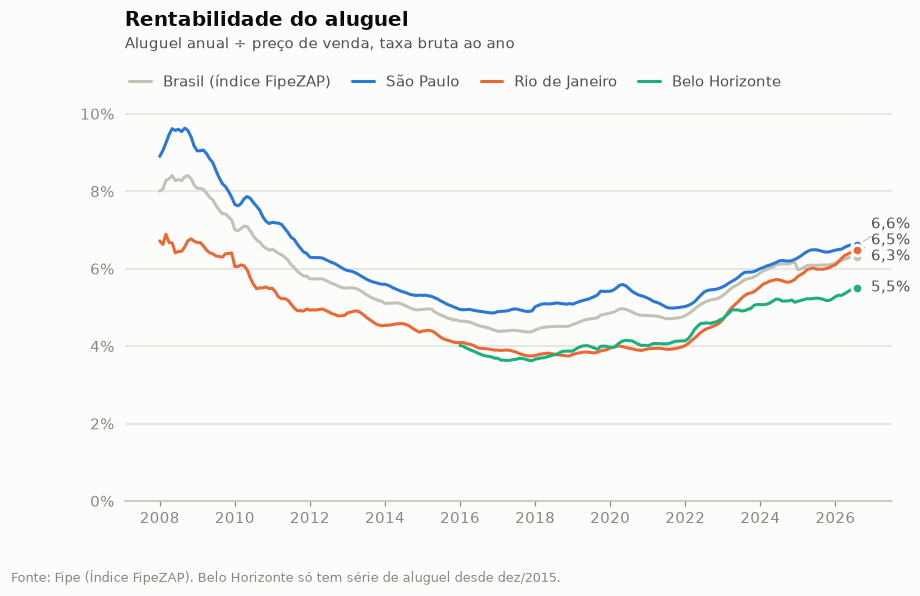

In [2]:
fig, ax = plt.subplots()
ax.plot(rentabilidade[NACIONAL], color=estilo.CINZA, label="Brasil (índice FipeZAP)")
for cidade in TRES_CIDADES:
    ax.plot(rentabilidade[cidade], color=estilo.CORES_CIDADES[cidade], label=cidade)

estilo.titulo(ax, "Rentabilidade do aluguel", "Aluguel anual ÷ preço de venda, taxa bruta ao ano", legenda=True)
estilo.eixo_pct(ax.yaxis)
ax.set_ylim(0, 0.105)
estilo.rotular_fins(ax, lambda v: pct(v, 1))
estilo.fonte(fig, "Fonte: Fipe (Índice FipeZAP). Belo Horizonte só tem série de aluguel desde dez/2015.")
plt.show()

In [3]:
linhas = []
for cidade in [NACIONAL, *TRES_CIDADES]:
    serie = rentabilidade[cidade].dropna()
    linhas.append(
        {
            "cidade": cidade,
            "hoje": pct(serie[ultimo], 1),
            "média": pct(serie.mean(), 1),
            "mínima": f"{pct(serie.min(), 1)} em {serie.idxmin():%m/%Y}",
            "máxima": f"{pct(serie.max(), 1)} em {serie.idxmax():%m/%Y}",
        }
    )
pd.DataFrame(linhas).set_index("cidade")

,hoje,média,mínima,máxima
cidade,,,,
Índice FipeZAP,"6,3%","5,6%","4,4% em 11/2017","8,4% em 05/2008"
São Paulo,"6,6%","6,1%","4,9% em 12/2016","9,6% em 09/2008"
Rio de Janeiro,"6,5%","4,9%","3,8% em 11/2017","6,9% em 03/2008"
Belo Horizonte,"5,5%","4,4%","3,6% em 12/2017","5,5% em 08/2026"


## Por que subiu: o aluguel correu na frente

Em reais de hoje, o m² de aluguel no índice nacional subiu mais de 40% em cinco anos. É o movimento que mais pesa
na conta de quem mora de aluguel, e ele aparece nas três cidades.

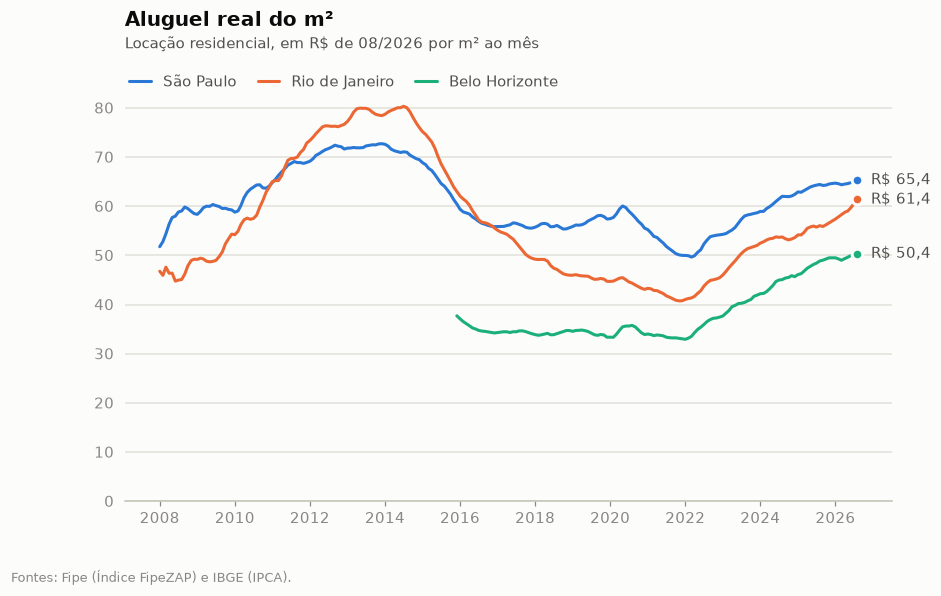

Variação real do aluguel em 5 anos:
  Índice FipeZAP: +41%
  São Paulo: +27%
  Rio de Janeiro: +48%
  Belo Horizonte: +51%


In [4]:
aluguel_real = total.pivot(index="data", columns="cidade", values="aluguel_preco_m2_real")

fig, ax = plt.subplots()
for cidade in TRES_CIDADES:
    ax.plot(aluguel_real[cidade], color=estilo.CORES_CIDADES[cidade], label=cidade)

estilo.titulo(ax, "Aluguel real do m²", f"Locação residencial, em R$ de {ultimo:%m/%Y} por m² ao mês", legenda=True)
estilo.eixo_br(ax.yaxis)
ax.set_ylim(0)
estilo.rotular_fins(ax, lambda v: f"R$ {br(v, 1)}")
estilo.fonte(fig, "Fontes: Fipe (Índice FipeZAP) e IBGE (IPCA).")
plt.show()

cinco_anos = aluguel_real.loc[ultimo] / aluguel_real.loc[ultimo - pd.DateOffset(years=5)] - 1
print("Variação real do aluguel em 5 anos:")
for cidade in [NACIONAL, *TRES_CIDADES]:
    print(f"  {cidade}: {pct(cinco_anos[cidade], sinal=True)}")

## A régua de comparação: o juro real sem risco

O aluguel costuma acompanhar a inflação ao longo do tempo, então a rentabilidade do aluguel se parece com um
**juro real**. A comparação natural é com o título público que paga inflação mais uma taxa fixa, o
**Tesouro IPCA+**.

Desde 2008 a disputa foi equilibrada: o aluguel bruto rendeu mais que o Tesouro IPCA+ em metade dos meses,
principalmente em 2012-2013 e de 2019 a 2021, quando o juro real caiu abaixo de 4%. Hoje a situação é a
oposta. Mesmo no ponto mais alto em uma década, o aluguel rende **menos** que o título público, que não tem
inquilino, vacância nem reforma.

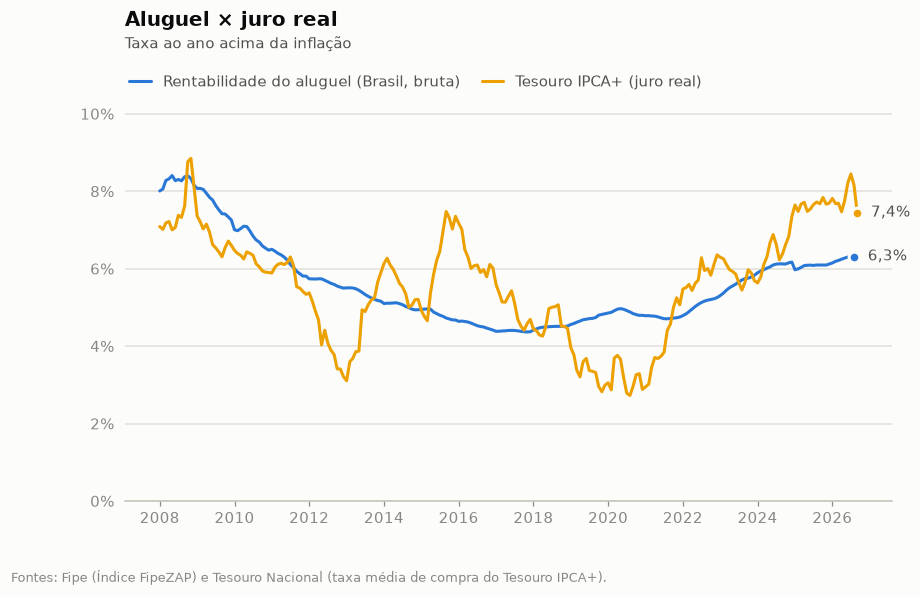

Meses em que o aluguel bruto rendeu mais que o Tesouro IPCA+: 50%
Diferença em 08/2026: −1,8 ponto percentual


In [5]:
tesouro = mensal["tesouro_ipca_taxa_aa"].loc["2008":]

fig, ax = plt.subplots()
ax.plot(rentabilidade[NACIONAL], color=estilo.AZUL, label="Rentabilidade do aluguel (Brasil, bruta)")
ax.plot(tesouro, color=estilo.AMARELO, label="Tesouro IPCA+ (juro real)")

estilo.titulo(ax, "Aluguel × juro real", "Taxa ao ano acima da inflação", legenda=True)
estilo.eixo_pct(ax.yaxis)
ax.set_ylim(0, 0.105)
estilo.rotular_fins(ax, lambda v: pct(v, 1))
estilo.fonte(fig, "Fontes: Fipe (Índice FipeZAP) e Tesouro Nacional (taxa média de compra do Tesouro IPCA+).")
plt.show()

diferenca = (rentabilidade[NACIONAL] - tesouro).dropna()
print(f"Meses em que o aluguel bruto rendeu mais que o Tesouro IPCA+: {pct((diferenca > 0).mean())}")
print(
    f"Diferença em {diferenca.index[-1]:%m/%Y}: {pct(diferenca.iloc[-1], 1, sinal=True).replace('%', '')} ponto percentual"
)

## Onde o aluguel rende mais

A rentabilidade varia bastante entre cidades. As mais altas estão no litoral paulista, no Recife e em Cuiabá; as
mais baixas, onde o preço de venda subiu muito nos últimos anos (Vitória, Curitiba) e o aluguel não acompanhou.

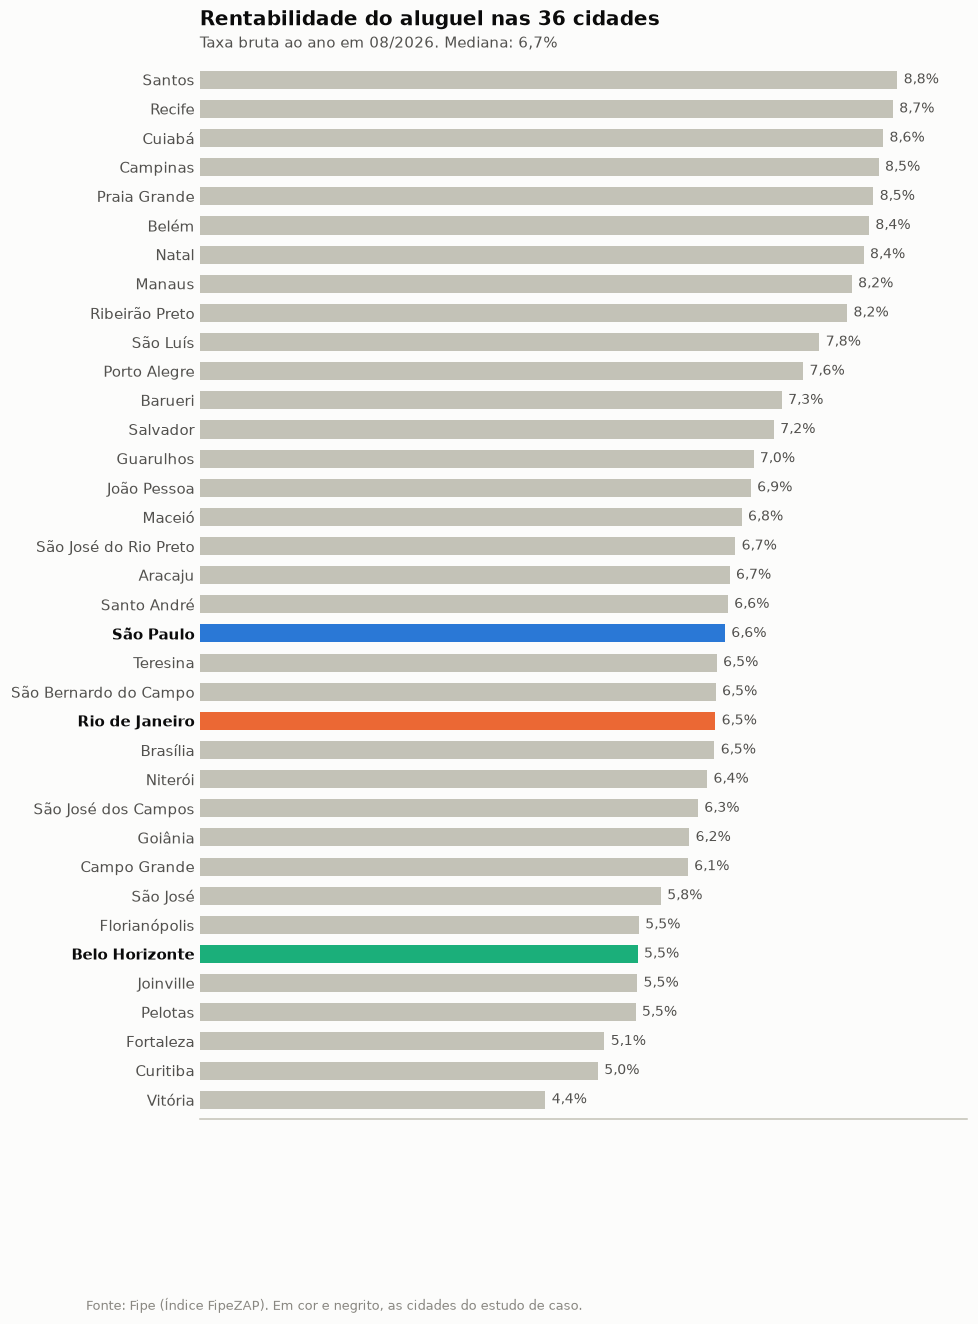

In [6]:
ranking = rentabilidade.loc[ultimo].drop(NACIONAL).dropna().sort_values()

fig, ax = plt.subplots(figsize=(9, 12.5))
cores = [estilo.CORES_CIDADES.get(cidade, estilo.CINZA) for cidade in ranking.index]
ax.barh(ranking.index, ranking, color=cores, height=0.62)
for posicao, valor in enumerate(ranking):
    ax.text(valor + 0.0008, posicao, pct(valor, 1), va="center", fontsize=9, color=estilo.TINTA_SECUNDARIA)

estilo.titulo(
    ax,
    f"Rentabilidade do aluguel nas {len(ranking)} cidades",
    f"Taxa bruta ao ano em {ultimo:%m/%Y}. Mediana: {pct(ranking.median(), 1)}",
)
ax.grid(False)
ax.set_xticks([])
ax.set_xlim(0, ranking.max() * 1.1)
ax.margins(y=0.01)
ax.tick_params(axis="y", length=0, labelcolor=estilo.TINTA_SECUNDARIA)
for rotulo in ax.get_yticklabels():
    if rotulo.get_text() in TRES_CIDADES:
        rotulo.set_fontweight("bold")
        rotulo.set_color(estilo.TINTA)
estilo.fonte(fig, "Fonte: Fipe (Índice FipeZAP). Em cor e negrito, as cidades do estudo de caso.")
plt.show()

## O que fica deste notebook

1. **Alugar ficou caro em relação a comprar.** A rentabilidade bruta do aluguel está em torno de 6,3% ao ano no
   índice nacional (6,6% em São Paulo, 6,5% no Rio, 5,5% em Belo Horizonte), o nível mais alto desde o começo da
   década de 2010. Em 2017 era 4,4%.
2. **Isso mexe diretamente na hipótese do projeto.** Quanto maior a rentabilidade do aluguel, mais o inquilino
   paga por ano em relação ao preço do imóvel, e menos sobra para investir. O argumento "alugar é barato" era
   muito mais forte em 2017 do que é hoje.
3. **Como investimento, hoje o aluguel perde para o juro real.** O Tesouro IPCA+ paga entre 7% e 8% acima da
   inflação, mais que o aluguel bruto, sem os custos e os riscos de ser proprietário. Nem sempre foi assim: em
   metade dos meses desde 2008 o aluguel rendeu mais.
4. O número é **bruto**. Para o dono que aluga, vacância, taxa de administração, manutenção e imposto de renda
   costumam levar de 20% a 35% do aluguel. O próximo notebook põe isso na conta.